## =====================================================

# Data Understading


## =====================================================

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
from xgboost import XGBClassifier
import lightgbm as lgb

from imblearn.over_sampling import SMOTE

In [4]:
df = pd.read_csv("dataset/credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:
df = df[df['person_emp_length'] <= 60]

df = df[df['person_age'] <= 100]

In [6]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31679.000000,3.167900e+04,31679.000000,31679.000000,28632.000000,31679.000000,31679.000000,31679.000000
mean,27.730673,6.649010e+04,4.782064,9659.962436,11.039701,0.215442,0.169610,5.809211
std,6.213427,5.276879e+04,4.034948,6334.360554,3.229409,0.411135,0.106269,4.059710
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.936600e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [7]:
df.shape

(31679, 12)

In [8]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [9]:
categorical_features = ['person_home_ownership',
                        'loan_intent', 'loan_grade',
                        'cb_person_default_on_file']
numeric_features = ['person_income',
                    'person_emp_length',
                    'loan_amnt', 'loan_int_rate',
                    'loan_percent_income',
                    'cb_person_cred_hist_length']

all_selected_cols = categorical_features + numeric_features + ['loan_status']
df_filtered = df[all_selected_cols]

df_encode = pd.get_dummies(df_filtered, columns=categorical_features, drop_first=True)

y = df_encode["loan_status"]

In [10]:
y.value_counts().sort_index()

loan_status
0    24854
1     6825
Name: count, dtype: int64

In [11]:
print(y.value_counts(normalize=True))

loan_status
0    0.784558
1    0.215442
Name: proportion, dtype: float64


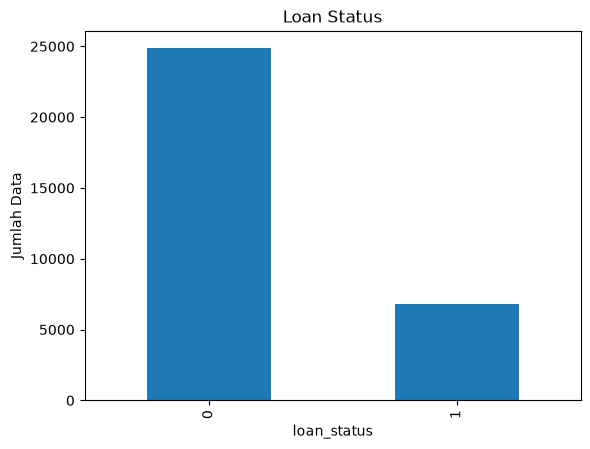

In [12]:
y.value_counts().sort_index().plot(kind='bar')
plt.ylabel("Jumlah Data")
plt.title("Loan Status")
plt.show()

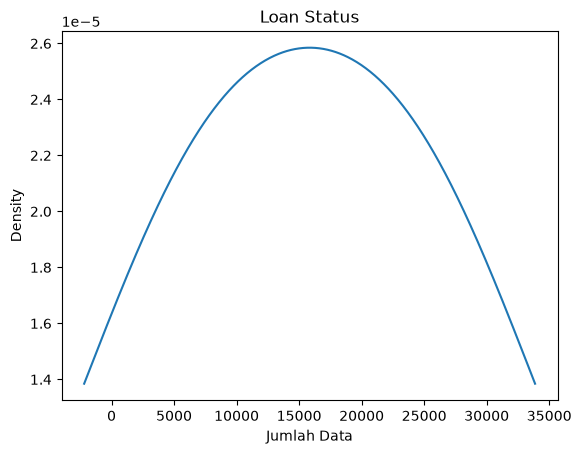

In [13]:
y.value_counts().sort_index().plot(kind='density')
plt.xlabel("Jumlah Data")
plt.title("Loan Status")
plt.show()

## =====================================================

# Data Preprocessing

## =====================================================

In [14]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length                0
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3047
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(157)

In [16]:
df = df.drop_duplicates()

In [17]:
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].mean())

In [18]:
df.isnull().sum()

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.shape

(31522, 12)

--------------------------------------------------------------------------------------------

### Split & Standard Scaler

--------------------------------------------------------------------------------------------

In [21]:
categorical_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
df_encode = pd.get_dummies(df, columns=categorical_features, drop_first=True)

y = df_encode["loan_status"]
X = df_encode.drop(columns=["loan_status"])

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.22,
    random_state=42,
    stratify=y,
)

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## =====================================================

# MODELING

## =====================================================

## Logistic Regression

--------------------------------------------------------------------------------------------

### LR With SMOTE

--------------------------------------------------------------------------------------------

In [24]:
smote = SMOTE(
    random_state = 42
)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

In [25]:
LG = LogisticRegression(max_iter=1000)
LG.fit(X_train_smote, y_train_smote)
LG_Prediction = LG.predict(X_test_scaled)

--------------------------------------------------------------------------------------------

In [26]:
accuracy = accuracy_score(y_test, LG_Prediction)
print("SMOTE")
print(f"LOGISTIC REGRESSION ACCURACY: {accuracy * 100:.4f}%")

SMOTE
LOGISTIC REGRESSION ACCURACY: 81.6871%


In [27]:
cm = confusion_matrix(y_test, LG_Prediction)
print(f"CONFUSION MATRIX: \n{cm}")

CONFUSION MATRIX: 
[[4495  942]
 [ 328 1170]]


In [28]:
cr = classification_report(y_test, LG_Prediction)
print(f"CLASSIFICATION REPORT: \n{cr}")

CLASSIFICATION REPORT: 
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5437
           1       0.55      0.78      0.65      1498

    accuracy                           0.82      6935
   macro avg       0.74      0.80      0.76      6935
weighted avg       0.85      0.82      0.83      6935



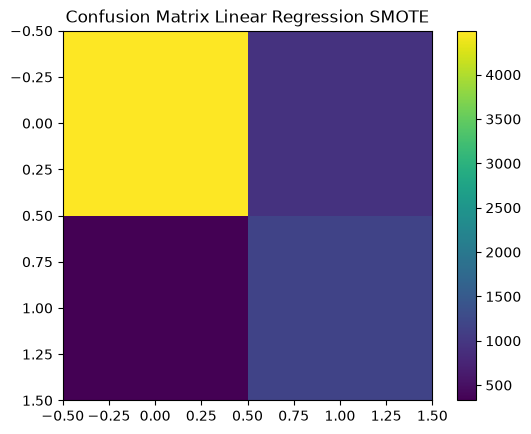

In [29]:
plt.imshow(cm)
plt.title("Confusion Matrix Linear Regression SMOTE")
plt.colorbar()

--------------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------------

### LR With Balance

--------------------------------------------------------------------------------------------

In [30]:
LG_balanced = LogisticRegression(
    class_weight ="balanced",
    max_iter=1000,
    random_state=42
    )
LG_balanced.fit(X_train_scaled, y_train)
LG_balanced_prediction = LG_balanced.predict(X_test_scaled)

In [31]:
accuracy = accuracy_score(y_test, LG_balanced_prediction)
print("Balanced")
print(f"LOGISTIC REGRESSION ACCURACY: {accuracy * 100:.4f}%")

Balanced
LOGISTIC REGRESSION ACCURACY: 81.9755%


In [32]:
cm_balanced = confusion_matrix(y_test, LG_balanced_prediction)
print(f"CONFUSION MATRIX: \n{cm_balanced}")

CONFUSION MATRIX: 
[[4506  931]
 [ 319 1179]]


In [33]:
cr = classification_report(y_test, LG_balanced_prediction)
print(f"CLASSIFICATION REPORT: \n{cr}")

CLASSIFICATION REPORT: 
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5437
           1       0.56      0.79      0.65      1498

    accuracy                           0.82      6935
   macro avg       0.75      0.81      0.77      6935
weighted avg       0.85      0.82      0.83      6935



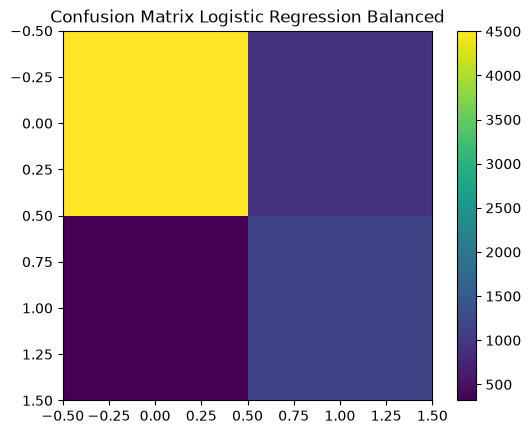

In [34]:
plt.imshow(cm_balanced)
plt.title("Confusion Matrix Logistic Regression Balanced")
plt.colorbar()

=========================================================================================================================

## XGBoost Model

--------------------------------------------------------------------------------------------

In [35]:
num_negatives = sum(y_train == 0)
num_positives = sum(y_train == 1)
calculated_weight = num_negatives / num_positives

In [36]:
XG = XGBClassifier(
    n_estimators = 1000,
    learning_rate = 0.1,
    scale_pos_weight = calculated_weight,
    random_state = 42
)

XG.fit(X_train_scaled, y_train)
XG_prediction = XG.predict(X_test_scaled)

In [37]:
AC = accuracy_score(y_test, XG_prediction)
print(f"{AC * 100:.4f}%")

93.0353%


In [38]:
cm = confusion_matrix(y_test, XG_prediction)
print(f"CONFUSION MATRIX: \n{cm}")

CONFUSION MATRIX: 
[[5269  168]
 [ 315 1183]]


In [39]:
CR = classification_report(y_test, XG_prediction)
print(f"CLASSIFICATION REPORT: \n{CR}")

CLASSIFICATION REPORT: 
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      5437
           1       0.88      0.79      0.83      1498

    accuracy                           0.93      6935
   macro avg       0.91      0.88      0.89      6935
weighted avg       0.93      0.93      0.93      6935



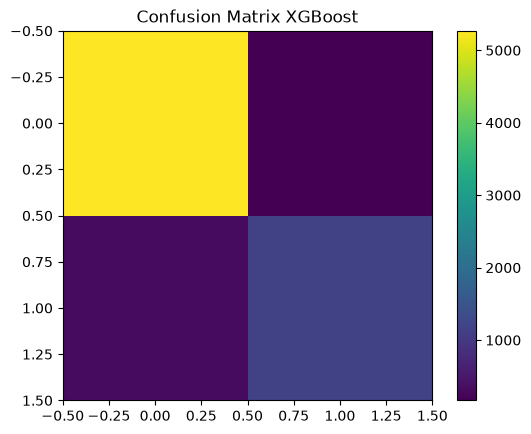

In [40]:
plt.imshow(cm)
plt.title("Confusion Matrix XGBoost")
plt.colorbar()

In [41]:
X_train_back = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_back = pd.DataFrame(X_test_scaled, columns=X_test.columns)

XG.fit(X_train_back, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


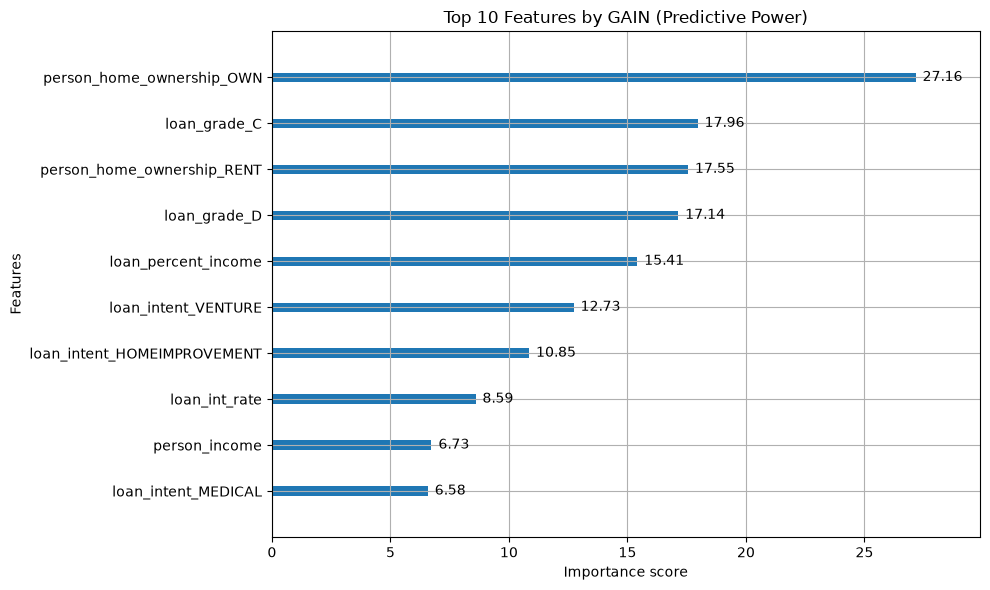

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))

xgb.plot_importance(XG, max_num_features=10, importance_type='gain', ax=ax, show_values=False)

for container in ax.containers:
    labels = [f'{v.get_width():.2f}' for v in container]
    ax.bar_label(container, labels=labels, padding=5)

plt.title("Top 10 Features by GAIN (Predictive Power)")
plt.tight_layout()
plt.show()

========================================================================================================

## LightGBM

------------------------------------------------------------------------------------------------

In [55]:
lgbm = lgb.LGBMClassifier(
    n_estimators = 1000,
    learning_rate = 0.1,
    scale_pos_weight = calculated_weight,
    random_state = 42
)

lgbm.fit(
    X_train_scaled,
    y_train,
    feature_name=list(X_train.columns)
)

lgbm_prediction = lgbm.predict(X_test_scaled)

[LightGBM] [Info] Number of positive: 5309, number of negative: 19278
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002696 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 978
[LightGBM] [Info] Number of data points in the train set: 24587, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.215927 -> initscore=-1.289561
[LightGBM] [Info] Start training from score -1.289561


D:\Project ML\Project 1\Real-Time Dynamic Credit Scoring System for E-Commerce Paylater\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [45]:
AC = accuracy_score(y_test, lgbm_prediction)
print(f"{AC * 100:.4f}%")

93.0065%


In [46]:
CM = confusion_matrix(y_test, lgbm_prediction)
print(f"CONFUSION MATRIX: \n{CM}")

CONFUSION MATRIX: 
[[5282  155]
 [ 330 1168]]


In [47]:
CR = classification_report(y_test, lgbm_prediction)
print(f"CLASSIFICATION REPORT: \n{CR}")

CLASSIFICATION REPORT: 
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      5437
           1       0.88      0.78      0.83      1498

    accuracy                           0.93      6935
   macro avg       0.91      0.88      0.89      6935
weighted avg       0.93      0.93      0.93      6935



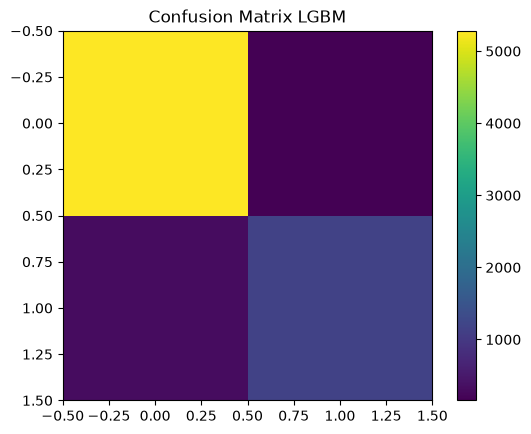

In [48]:
plt.imshow(CM)
plt.title("Confusion Matrix LGBM")
plt.colorbar()

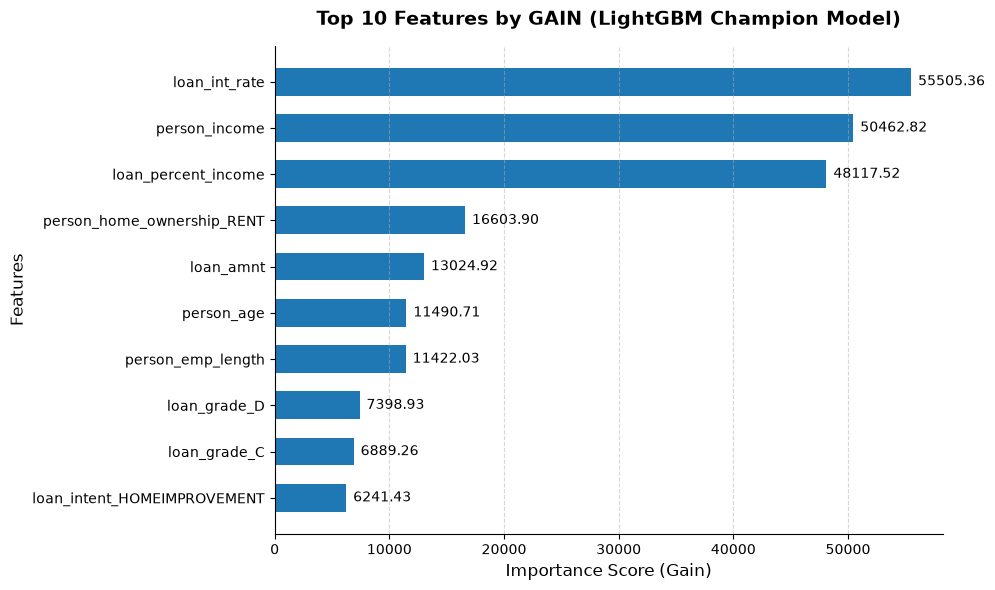

In [56]:
# 1. Extract LightGBM features and their corresponding gain importance
feature_names = lgbm.feature_name_
gain_importances = lgbm.booster_.feature_importance(importance_type='gain')

# 2. Put them into a clean Pandas Series and sort them
df_importance = pd.Series(gain_importances, index=feature_names).sort_values(ascending=True)

# 3. Grab only the top 10 most powerful drivers
df_top10 = df_importance.tail(10)

# 4. Initialize standard Matplotlib bars
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_top10.index, df_top10.values, color='#1f77b4', height=0.6)

# 5. Add custom rounded labels to the right side of the bars
ax.bar_label(bars, fmt='%.2f', padding=5)

# 6. Aesthetic cleanup
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.title("Top 10 Features by GAIN (LightGBM Champion Model)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Importance Score (Gain)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()

------------------------------------------------------------------------------------------------------

D:\Project ML\Project 1\Real-Time Dynamic Credit Scoring System for E-Commerce Paylater\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


XGBoost Score:             0.9472
LightGBM Score:            0.9476
Logistic Regression Score: 0.8741


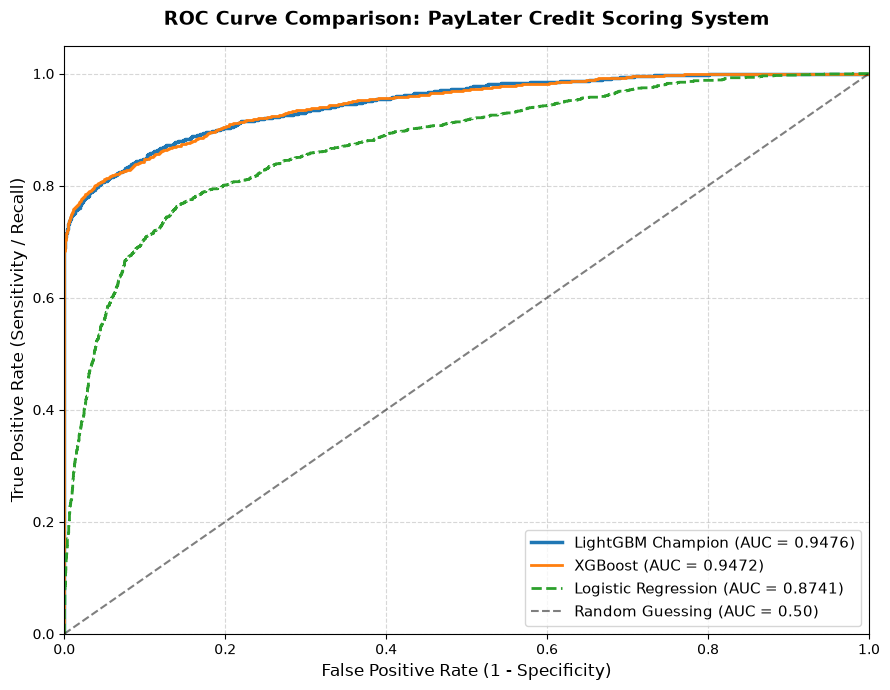

In [58]:
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Predict PROBABILITIES for all three models (Take column 1 for Class 1)
xgb_probs = XG.predict_proba(X_test_scaled)[:, 1]
lgbm_probs = lgbm.predict_proba(X_test_scaled)[:, 1]
lr_probs = LG_balanced.predict_proba(X_test_scaled)[:, 1]  # Using your balanced linear model

# 2. Calculate the raw ROC-AUC scores
xgb_auc = roc_auc_score(y_test, xgb_probs)
lgbm_auc = roc_auc_score(y_test, lgbm_probs)
lr_auc = roc_auc_score(y_test, lr_probs)

print(f"XGBoost Score:             {xgb_auc:.4f}")
print(f"LightGBM Score:            {lgbm_auc:.4f}")
print(f"Logistic Regression Score: {lr_auc:.4f}")

# 3. Calculate False Positive Rates and True Positive Rates for the curves
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)
lgbm_fpr, lgbm_tpr, _ = roc_curve(y_test, lgbm_probs)
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)

# 4. Plot the comparison chart
plt.figure(figsize=(9, 7))

# Plot the 3 model lines
plt.plot(lgbm_fpr, lgbm_tpr, label=f'LightGBM Champion (AUC = {lgbm_auc:.4f})', linewidth=2.5, color='#1f77b4')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_auc:.4f})', linewidth=2, color='#ff7f0e')
plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.4f})', linewidth=2, linestyle='--', color='#2ca02c')

# Plot the diagonal baseline (Random guessing reference line)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guessing (AUC = 0.50)')

# Aesthetic formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('ROC Curve Comparison: PayLater Credit Scoring System', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11)
plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

================================================================================================================

In [60]:
import joblib

model_filename = "model/lightgbm_paylater.pkl"
joblib.dump(lgbm, model_filename)

print(f"THe model successfully saved as: {model_filename}")

THe model successfully saved as: lightgbm_paylater.pkl


In [61]:
scaler_filename = 'model/credit_data_scaler.pkl'
joblib.dump(scaler, scaler_filename)

print(f"⚙️ Preprocessing scaler successfully saved as: {scaler_filename}")

⚙️ Preprocessing scaler successfully saved as: credit_data_scaler.pkl
